# Imports

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output
import scipy.optimize

# Global parameters
Nx = 51 # Število polj v x smeri
Ny = 51 # Število polj v y smeri

S_c = 4 #Kritična meja za zdrs
st_zrn = 1

T_FIN = 100_000 #Števiko iteracij, ki jih simuliramo

#Lokacija kamer zrna padajo na ploščo
cx=int(Nx/2) 
cy=int(Ny/2)

pos=[[cx,cy]]

# Testno območje

In [14]:
array = np.array([0,1,0,1,1,1,0])
test = (array == 0)

print(test,len(test),np.sum(test))

[ True False  True False False False  True] 7 3


# Funkcije

In [15]:
#Prototip funkcij za fitanje
def f_lin(x,A,B):
    return A*x+B

def f_exp(x,A,B):
    return A*np.exp(-x*B)

def f_pow(x,A,B):
    return A*np.power(x,B)

def r_values(matrika):
    perr = matrika[0,1]/np.sqrt(matrika[0,0]*matrika[1,1])
    return perr

def ma(w,podatki):
    #Moving Averge => ma
    #overlaping.
    x = []
    y = []
    for s in range(0,len(podatki)-w):
        y.append(np.mean(podatki[s:s+w]))
        x.append(int(w/2)+s)
    return [x,y]

def init_S(Nx,Ny):
    return np.zeros([Nx,Ny],int)

def init_F(Nx,Ny,pos,st_zrn):
    F = np.zeros([Nx,Ny],int)
    #pos -> je seznam koordinat
    for xy in pos:
        F[xy[0],xy[1]]=st_zrn
    return F

def TBW_model(i,j,S,S_th):
    global size
    
    ip = i+1
    im = i-1
    jp = j+1
    jm = j-1
    
    if S[i,j] > S_th:#Več od štiri #Plaz!!!!!!
        size+=1
        S[i,j]-=4
        
        if ip%(Nx-1) != 0:
            S[ip,j] += 1
            TBW_model(ip,j,S,S_th)
            
        if im%(Nx) != 0:
            S[im,j]+=1
            TBW_model(im,j,S,S_th)
            
        if jp%(Ny-1) != 0:
            S[i,jp]+=1
            TBW_model(i,jp,S,S_th)
            
        if jm%Ny != 0:
            S[i,jm]+=1
            TBW_model(i,jm,S,S_th)
    return S

# Main

Porabljen čas za 1000 iteracij je 0.840 (99000 od 100000)


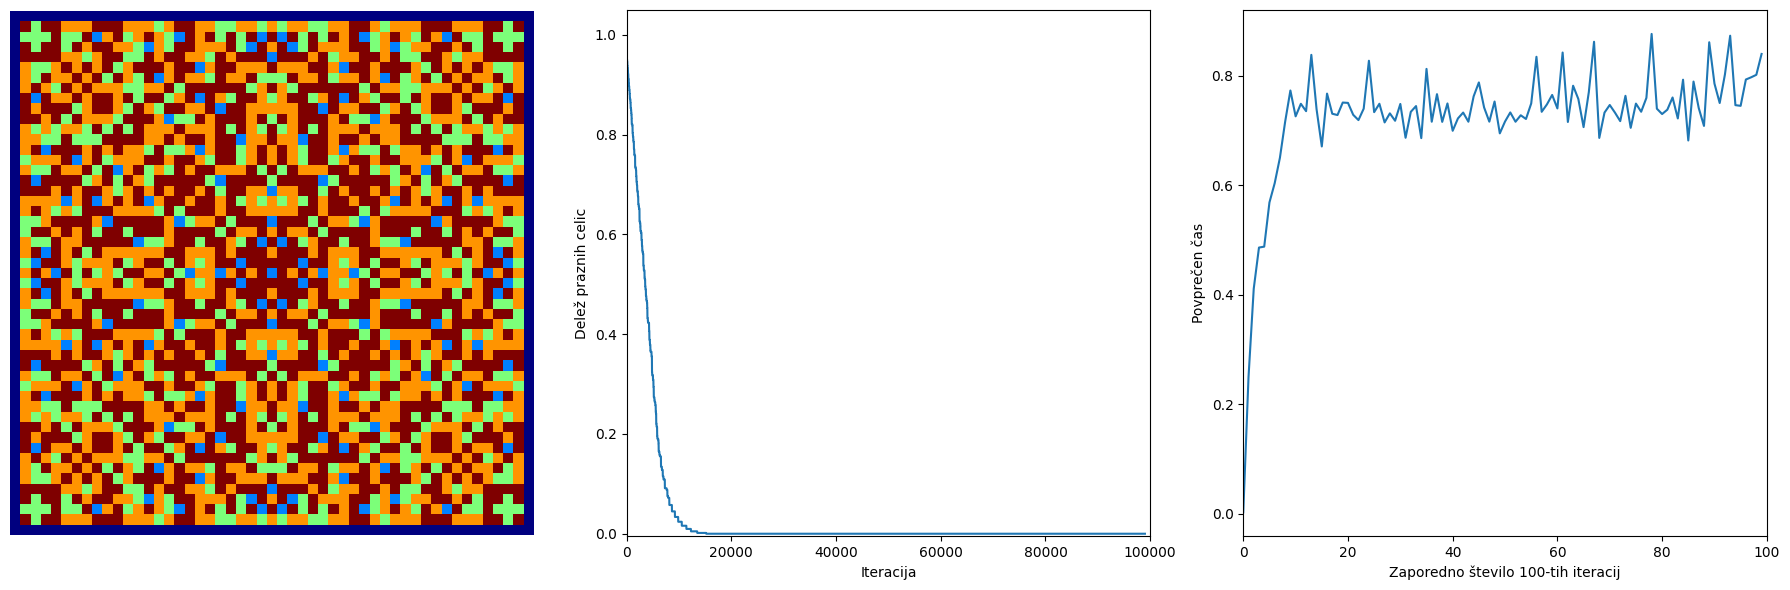

In [16]:
S=init_S(Nx,Ny)
F=init_F(Nx,Ny,pos,st_zrn)

plazovi=[]
dt_list=[]
frac_list=[]

start=time.time()


tau=1000

TFIN = T_FIN

for iteracija in range(TFIN):
    S=S+F
    size=0
    S = TBW_model(cx,cy,S,S_c)
    
    #Delež polnih celic
    frac = (np.sum(S==0)-(2*Nx+2*Ny-4))/((Nx-1)*(Ny-1))
    frac_list.append(frac)
    
    
    if size>0:
        plazovi.append(size)
    
    if (iteracija % tau)==0:
        clear_output(wait=True)
        end=time.time()
        dt = end - start
        print(f'Porabljen čas za {tau} iteracij je {dt:.3f} ({iteracija} od {TFIN})')
        
        #Trajanje tau iteracij
        dt_list.append(dt)
        
        start = time.time()
        
        
        plt.figure(figsize=(18,6))
        plt.subplot(131)
        plt.imshow(S,cmap="jet",vmin=0,vmax=4)
        plt.axis("off")
        
        plt.subplot(132)
        plt.plot(frac_list)
        plt.xlabel("Iteracija")
        plt.ylabel("Delež praznih celic")
        plt.ylim(-0.005,1.05)
        plt.xlim(0,TFIN)
        
        plt.subplot(133)
        plt.plot(dt_list)
        plt.xlabel("Zaporedno število 100-tih iteracij")
        plt.ylabel("Povprečen čas")
        plt.xlim(0,(TFIN/tau))
        
        plt.tight_layout()
        plt.show()

# Slika 1

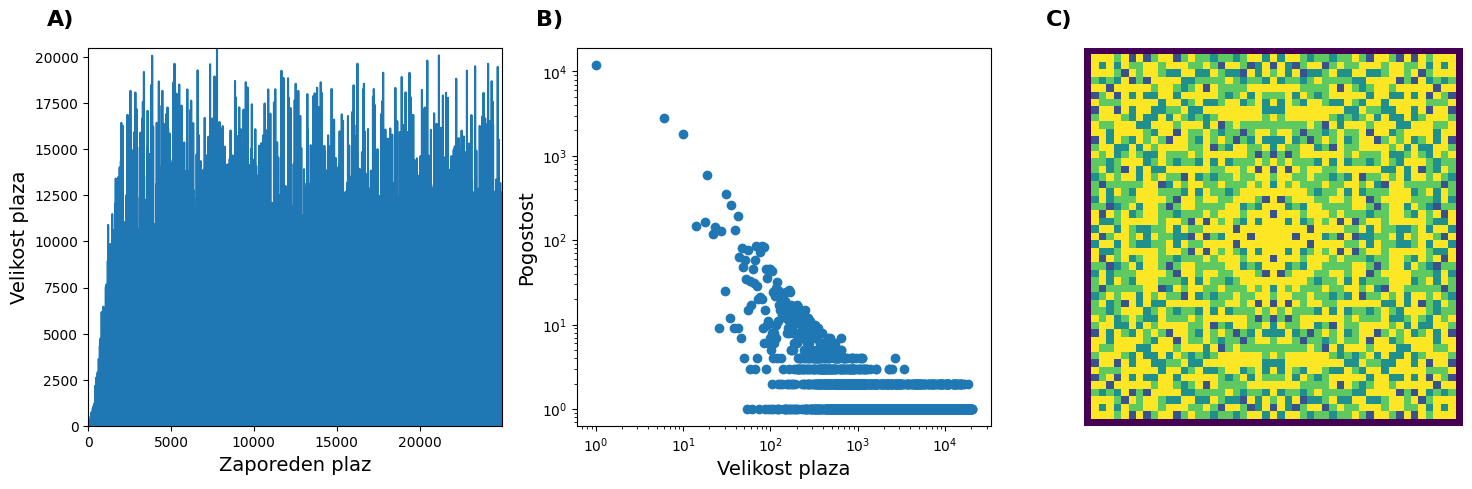

In [17]:
sirina = 15 #inch
visina = 5 #inch

fig=plt.figure(figsize=(sirina,visina))
#A
ax=fig.add_subplot(131)
ax.plot(plazovi)
ax.set_xlabel("Zaporeden plaz",fontsize=14)
ax.set_ylabel("Velikost plaza",fontsize=14)
ax.set_xlim(0,len(plazovi))
ax.set_ylim(0,max(plazovi))

ax.text(-0.1,1.10,"A)",
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top")

#B
ax=fig.add_subplot(132)

freq={}
for v in plazovi:
    if v not in freq:
        freq[v]=0
    freq[v]+=1
    

x=[v for v in freq]
y=[freq[v] for v in freq]

ax.scatter(x,y)
ax.set_ylabel("Pogostost",fontsize=14)
ax.set_xlabel("Velikost plaza",fontsize=14)
ax.set_xscale("log")
ax.set_yscale("log")


ax.text(-0.1,1.10,"B)",
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top")



#C
ax=fig.add_subplot(133)
ax.imshow(S)
ax.axis("off")

ax.text(-0.1,1.10,"C)",
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top")

plt.tight_layout()
plt.savefig("Slika_01.png",dpi=150)
plt.savefig("Slika_01.jpg",dpi=150)
plt.savefig("Slika_01.svg")
plt.show()

# Slika 2

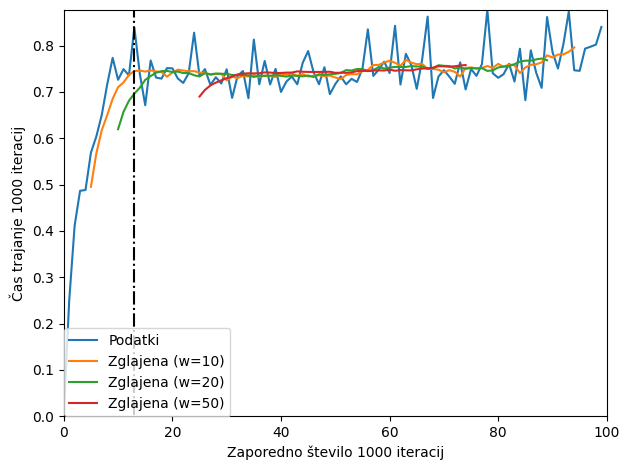

In [ ]:
#Predhodna določitev odvodov
x1,y1=ma(10,dt_list)

dy=np.diff(y1)
w=10
x1,y1=ma(w,dy)
y1=np.array(y1)
x1=np.array(x1)
#Določimo prvo vrednost, ko odvod postane negativen
START = x1[y1<0][0]



plt.plot(dt_list,label="Podatki")
for w in [10,20,50]:
    x1,y1=ma(w,dt_list)
    plt.plot(x1,y1,label=f'Zglajena (w={w})')

plt.xlabel(f"Zaporedno število {tau} iteracij")
plt.ylabel(f"Čas trajanje {tau} iteracij")
plt.xlim(0,len(dt_list))
plt.ylim(0,max(dt_list))

#plt.vlines(x,y_min,y_max)
#plt.hlines(y,x_min,x_max)

plt.vlines(START,min(dt_list),max(dt_list),color="black",ls="-.")

plt.legend(loc=[0,0])

plt.tight_layout()
plt.savefig("Slika_02.jpg",dpi=150)
plt.show()

# Slika 3

C:\Users\Rene\AppData\Local\Temp\ipykernel_38748\263899901.py:6: RuntimeWarning: overflow encountered in exp
  return A*np.exp(-x*B)


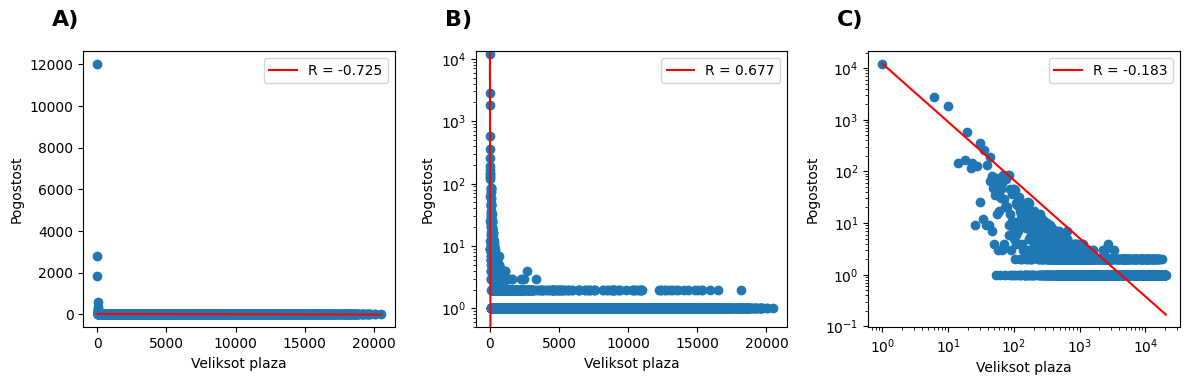

In [22]:
sirina=12#inch
visina=4#inch

freq={}
for v in plazovi:
    if v not in freq:
        freq[v]=0
    freq[v]+=1

x=[v for v in freq]
y=[freq[v] for v in freq]


fig=plt.figure(figsize=(sirina,visina))
#lin(x)-lin(y)
ax=fig.add_subplot(131)
ax.scatter(x,y,zorder=2)

popt, pcov = scipy.optimize.curve_fit(f_lin,x,y)
A,B=popt
r=r_values(pcov)

x1=sorted(x)
x1=np.array(x1)
y1=f_lin(x1,A,B)
p1,=ax.plot(x1,y1,zorder=2,color="red")
ax.legend([p1],['R = %.3f'%(r)], loc=1)
ax.set_xlabel("Veliksot plaza")
ax.set_ylabel("Pogostost")
ax.text(-0.1,1.15,"A)",
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top")

#lin(x)-log(y)
ax=fig.add_subplot(132)
ax.scatter(x,y)
ax.set_yscale("log")

popt, pcov = scipy.optimize.curve_fit(f_exp,x,y)
r=r_values(pcov)

A,B=popt

x1=sorted(x)
x1=np.array(x1)
y1=f_exp(x1,A,B)
p1,=ax.plot(x1,y1,zorder=2,color="red")
ax.legend([p1],['R = %.3f'%(r)], loc=1)
ax.set_ylim(0.5,max(y)*1.1)
ax.set_xlabel("Veliksot plaza")
ax.set_ylabel("Pogostost")
ax.text(-0.1,1.15,"B)",
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top")

#log(x)-log(y)
ax=fig.add_subplot(133)
ax.scatter(x,y)
ax.set_yscale("log")
ax.set_xscale("log")

popt, pcov = scipy.optimize.curve_fit(f_pow,x,y)
r=r_values(pcov)
A,B=popt

x1=sorted(x)
x1=np.array(x1)
y1=f_pow(x1,A,B)
p1,=ax.plot(x1,y1,zorder=2,color="red")
ax.legend([p1],['R = %.3f'%(r)], loc=1)

ax.set_xlabel("Veliksot plaza")
ax.set_ylabel("Pogostost")
ax.text(-0.1,1.15,"C)",
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top")

plt.tight_layout()
plt.show()

# Domača naloga

Predpostavimo, da spremenljivka $x$ vsebuje vrednosti od velikosti plaza in spremenljivka $y$, vrednosti o pojavnosti plaza določene velikosti. Analizirajte porazdelitev velikost plazov na takšen način, da podatke o porazdelitvi velikosti plazov linearizirate na dva dva različna načina.

- Linearizirajte samo $y$ spremenljivko in ji prilagodite linearno funkcijo.
- Linearizirajte $y$ in $x$ spremenljivko in porazdelitvi prilagodite linearno funkcijo.

<font style="bold">Rezultate prikažite grafično.<font>

# Dodatna naloga

Uporabite program in preučite, kako vpliva mejna vrednost strmine, pri kateri se sproži plaz na dinamiko sistema. Rezultate komentirajte.

Program preoblikujte tako, da se vsako iteracijo doda le eno zrno peska. Ko strmina v določenem polju preseže kritično vrednost, pa se le eno zrno odda. Kateri od sosedov pa prejme zrno, se določi naključno. Na podoben način analiziraj dinamiko sistema in komentiraj rezultate.